# Mutation-age accuracy and matching performance

Detailed report and supporting diagnostics, 22 October 2026.
The report includes the root-copying mechanism, rescaling controls, true-topology
controls, HPC cache audit, occupancy analysis and local native matching timings.
Expensive experiments are saved with their source scripts and configuration.

In [1]:
import pathlib

import IPython.display as display
import pandas as pd

repository_dir = pathlib.Path.cwd()

Metric / frequency group,Full HMM,AF 0.01,AF 0.1
"Pearson r, all ages",0.720,0.568,0.604
"Pearson r, log10 ages",0.771,0.765,0.765
"Spearman ρ, all ages",0.728,0.720,0.722
"Pearson r, DAF<1%",0.375,0.326,0.331
"Pearson r, DAF 1–50%",0.553,0.411,0.487
"Pearson r, DAF≥50%",0.288,0.195,0.204
"Spearman ρ, DAF 1–50%",0.745,0.751,0.753
"Spearman ρ, DAF≥50%",0.434,0.424,0.430
"RMSE, generations","4,619","6,492","5,981"
"Maximum estimated age, generations","166,926","444,678","374,797"

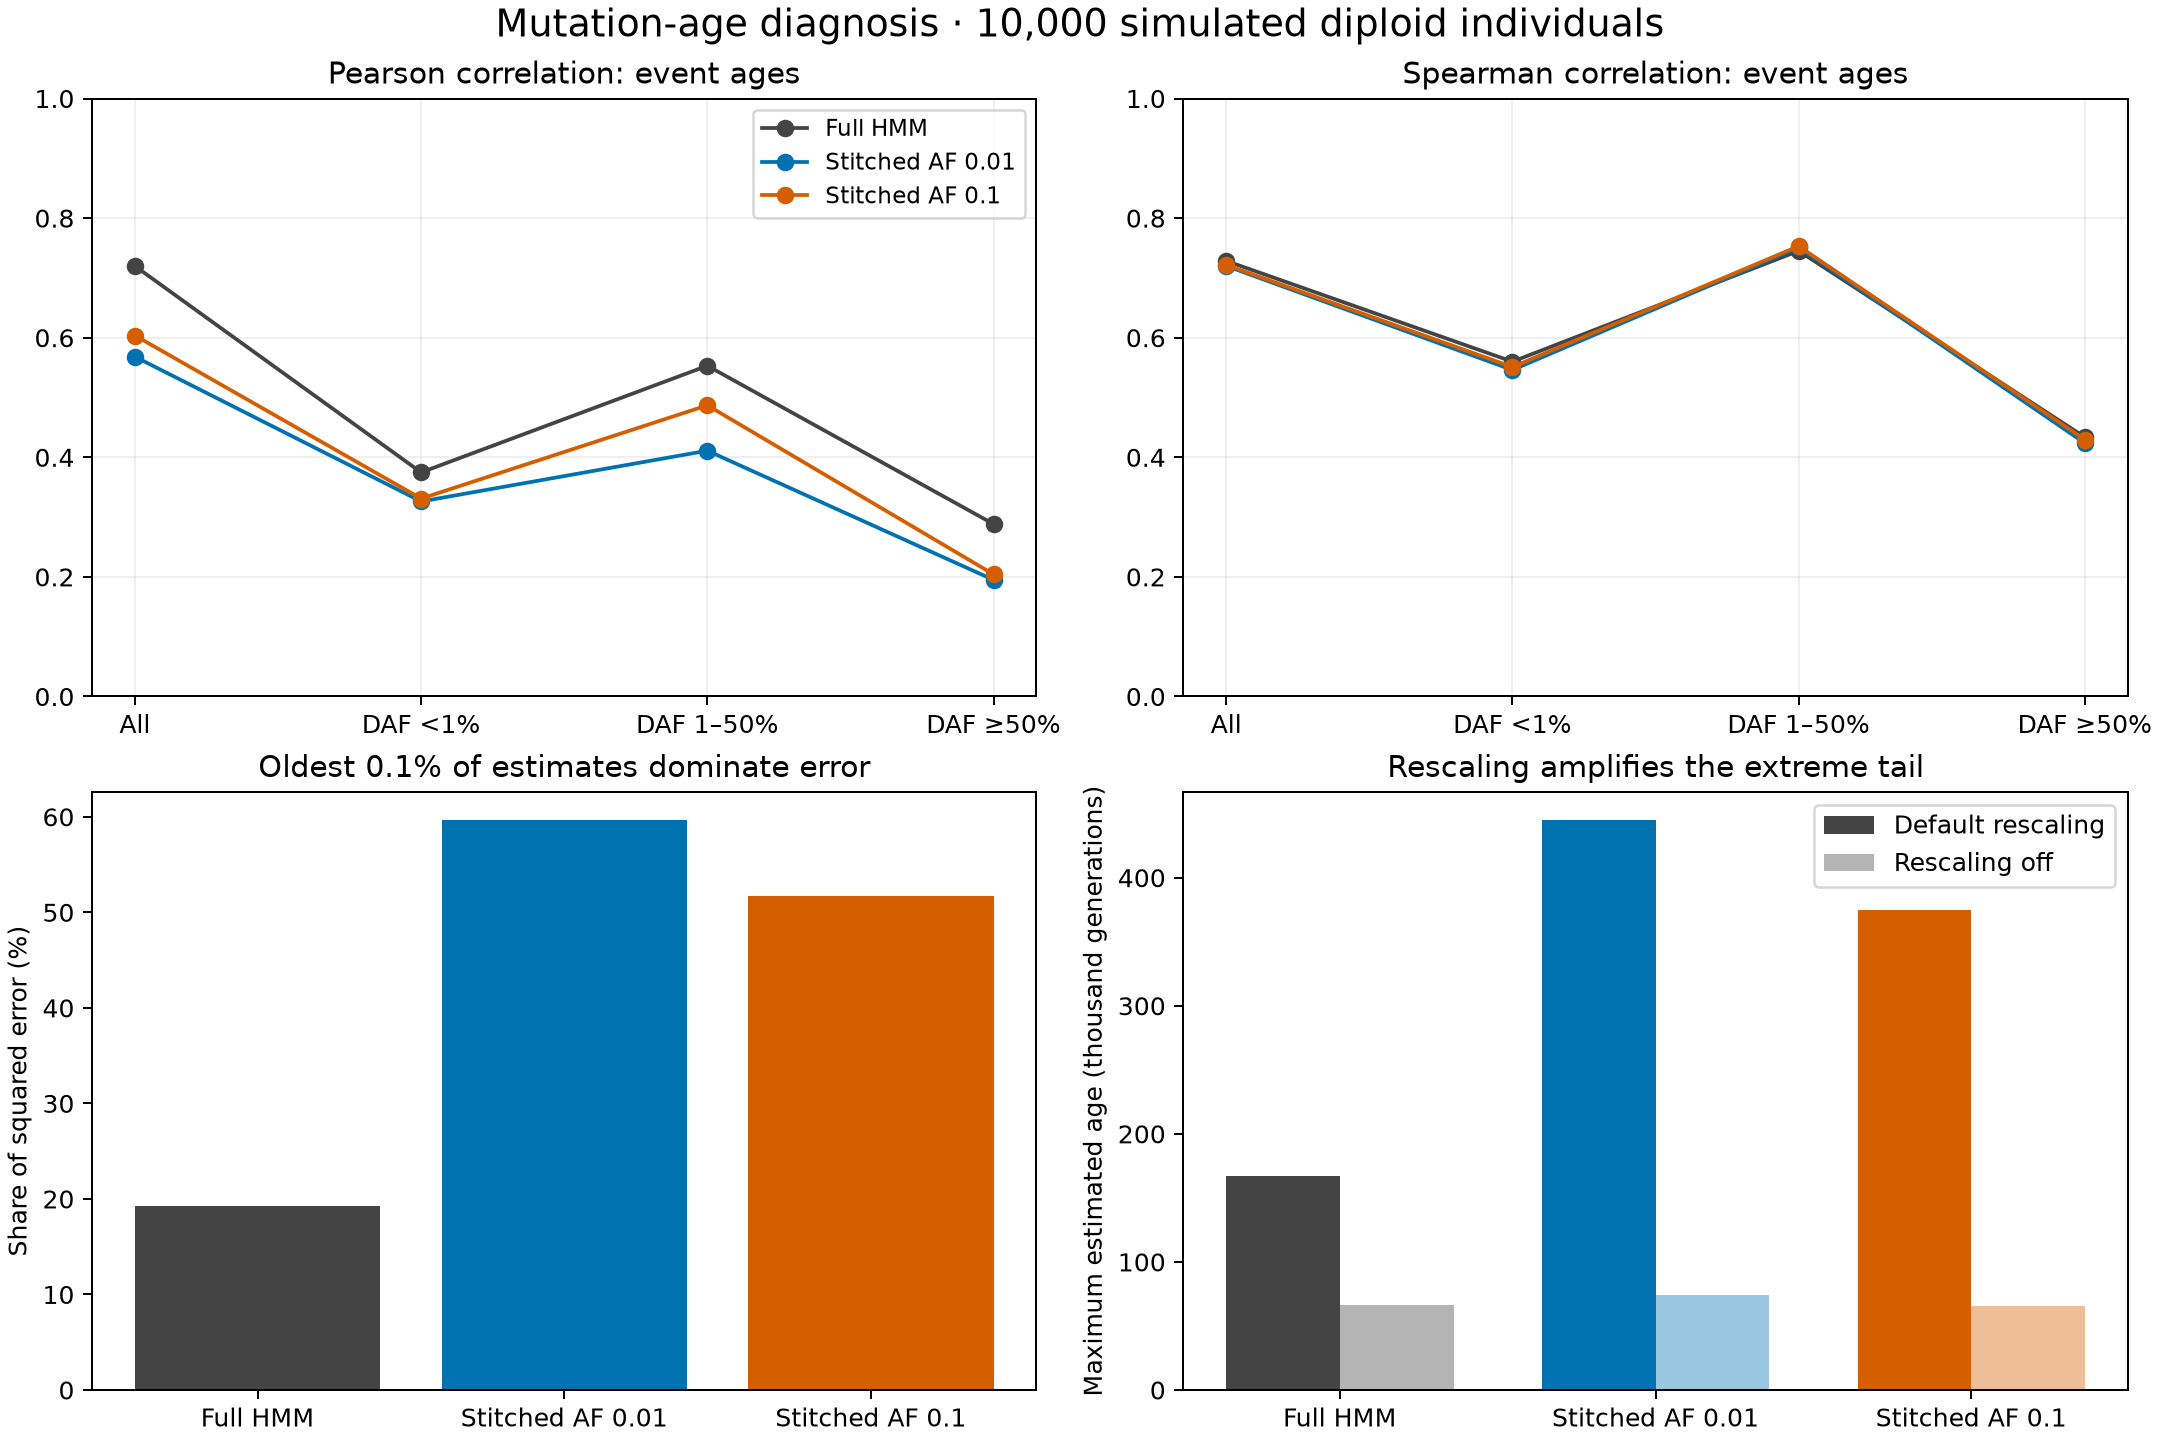
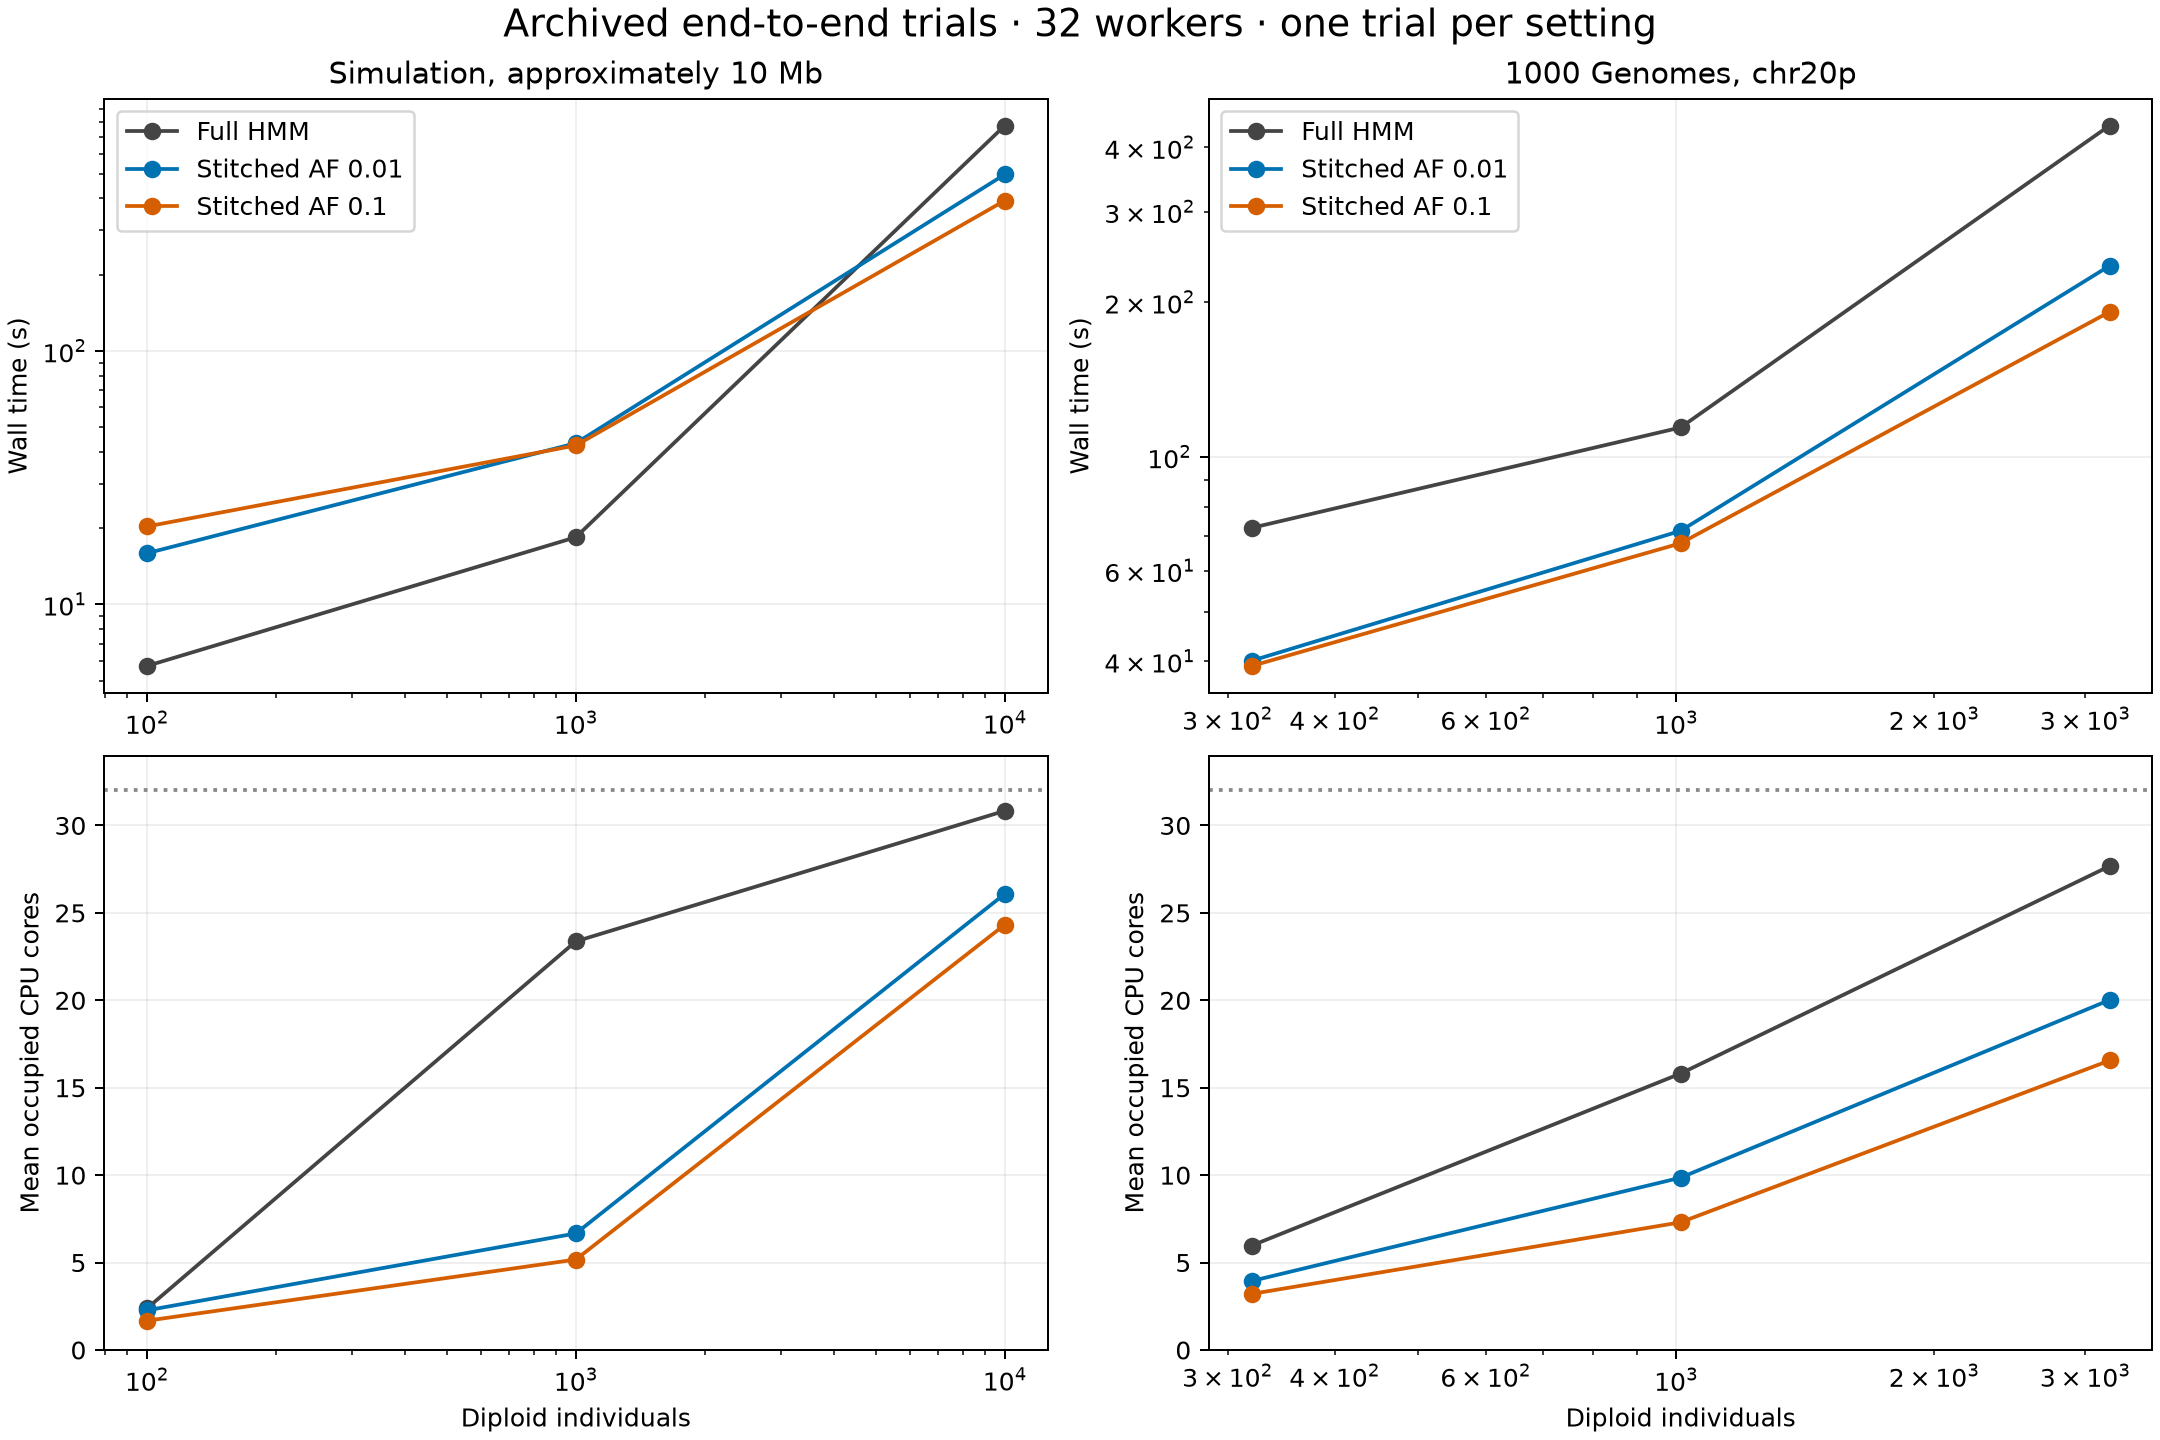
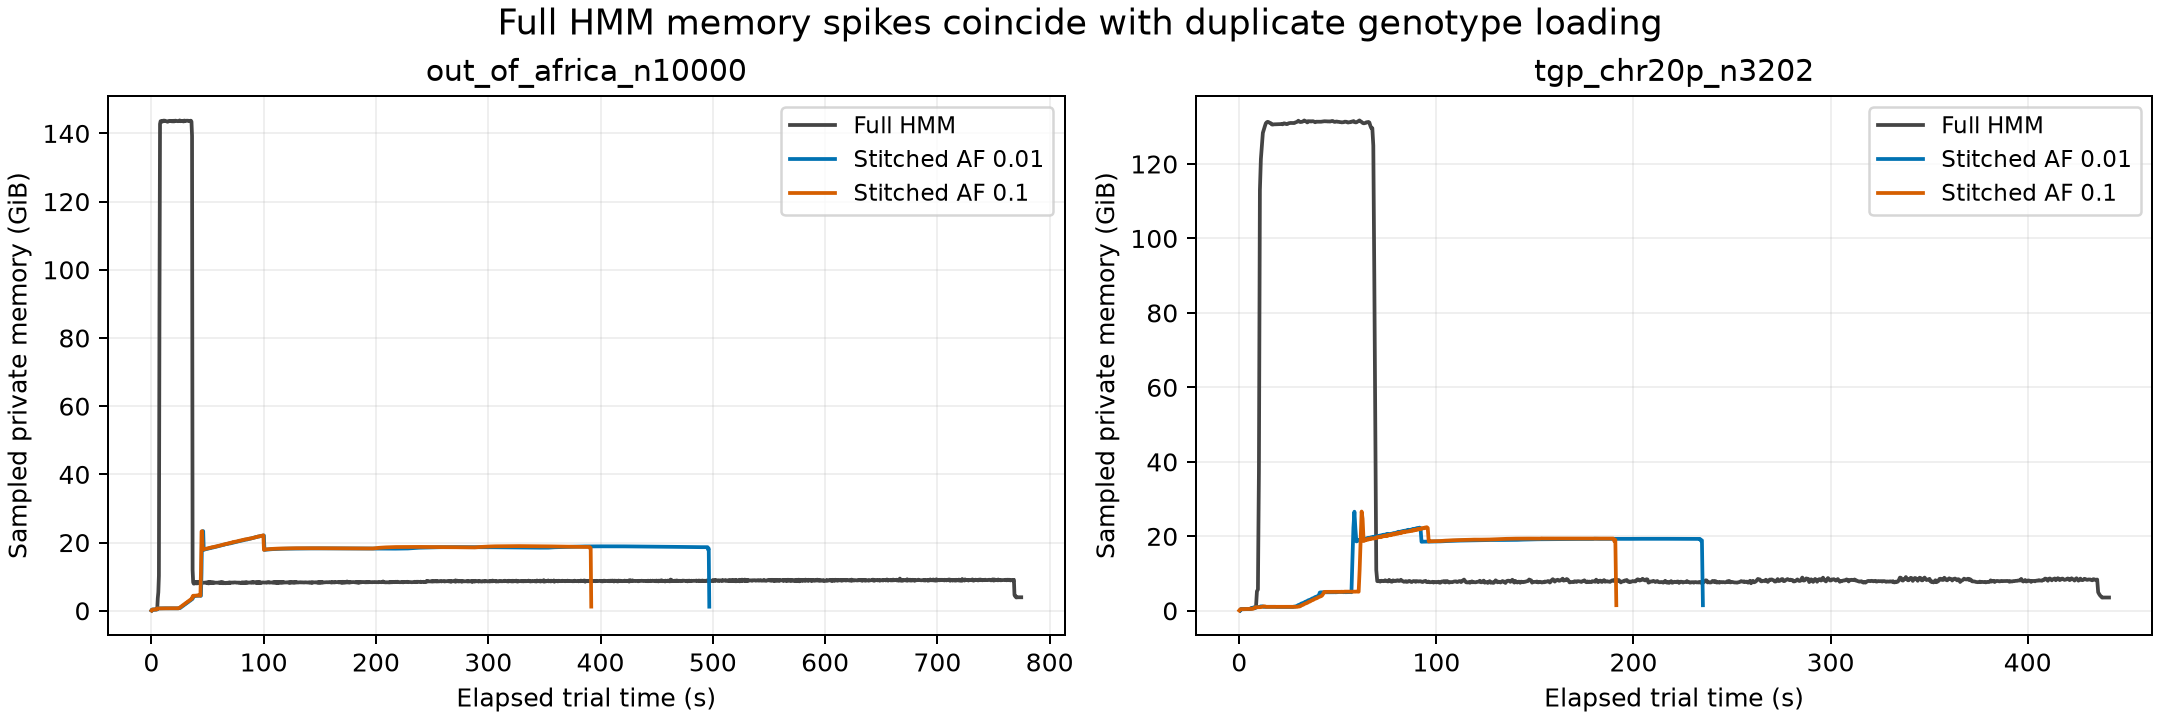

In [2]:
notebook_dir = (
    pathlib.Path(__file__).resolve().parent
    if "__file__" in globals()
    else pathlib.Path.cwd()
)
repository_dir = (
    notebook_dir if (notebook_dir / "data").is_dir() else notebook_dir.parent.parent
)
artifact_dir = repository_dir / "data/ch5/mutation_age_performance_review_2026_10_22"
display.HTML((artifact_dir / "mutation_age_performance_report.html").read_text())

The following cells expose the evidence tables for inspection. No original
experiment caches are changed and no ARG metrics are calculated.

In [3]:
age_metrics = pd.read_csv(artifact_dir / "age_metrics.csv")
display.display(age_metrics)

,archive,dataset,bin,method,n,r,r_log,rho,mae,medae,bias,rmse,median_ratio,oracle_r,midpoint_r,oracle_rmse,root_parent_fraction,outside_true_edge,frequency_changed
0,hpc_perf1_diagnostics,out_of_africa_n100_10mbp_error,all,full_hmm,43258,0.715642,0.830976,0.853678,4859.026067,1755.538867,-750.007104,9529.257211,0.825696,0.910722,0.784776,5259.833568,0.204494,0.417310,0.243955
1,hpc_perf1_diagnostics,out_of_africa_n100_10mbp_error,all,af_0.01,43258,0.711273,0.830644,0.853602,4895.631395,1764.480757,-733.470956,9635.620910,0.824180,0.910722,0.779281,5259.833568,0.204494,0.418790,0.243955
2,hpc_perf1_diagnostics,out_of_africa_n100_10mbp_error,all,af_0.1,43258,0.705328,0.830975,0.853982,4912.249782,1746.773101,-694.238488,9818.266372,0.827304,0.910722,0.772713,5259.833568,0.204494,0.414744,0.243955
3,hpc_perf1_diagnostics,out_of_africa_n100_10mbp_error,0.01 ≤ DAF < 0.5,full_hmm,37650,0.688903,0.796271,0.818265,3893.079017,1380.874774,-1062.641514,7926.044648,0.779893,0.901546,0.760278,4521.963754,0.131979,0.424568,0.197131
4,hpc_perf1_diagnostics,out_of_africa_n100_10mbp_error,0.01 ≤ DAF < 0.5,af_0.01,37650,0.687004,0.795915,0.818203,3912.654339,1382.017028,-1059.828987,7952.513189,0.778211,0.901546,0.757814,4521.963754,0.131979,0.425764,0.197131
5,hpc_perf1_diagnostics,out_of_africa_n100_10mbp_error,0.01 ≤ DAF < 0.5,af_0.1,37650,0.688075,0.796208,0.818640,3906.634115,1380.001647,-1046.372297,7946.822368,0.781671,0.901546,0.760265,4521.963754,0.131979,0.421594,0.197131
6,hpc_perf1_diagnostics,out_of_africa_n100_10mbp_error,DAF ≥ 0.5,full_hmm,5608,0.443541,0.569568,0.558655,11344.030782,7363.729234,1348.902583,16693.847208,1.104314,0.825356,0.538903,8724.833613,0.691334,0.368581,0.558310
7,hpc_perf1_diagnostics,out_of_africa_n100_10mbp_error,DAF ≥ 0.5,af_0.01,5608,0.434176,0.566769,0.556933,11494.969153,7439.167732,1457.573951,17075.910891,1.109118,0.825356,0.524696,8724.833613,0.691334,0.371969,0.558310
8,hpc_perf1_diagnostics,out_of_africa_n100_10mbp_error,DAF ≥ 0.5,af_0.1,5608,0.421572,0.567890,0.559827,11663.574650,7439.826645,1669.855290,17877.414634,1.111517,0.825356,0.505797,8724.833613,0.691334,0.368759,0.558310
9,hpc_perf1_diagnostics,out_of_africa_n1000_10mbp_error,all,full_hmm,95387,0.724967,0.847921,0.853934,2566.682183,346.251144,-484.940300,7173.517020,0.796149,0.933116,0.775838,3552.803698,0.094352,0.488494,0.464770


In [4]:
for name in [
    "root_copying",
    "preprocessing",
    "root_error",
    "large_control_metrics",
    "control_metrics",
    "cache_audit",
]:
    display.display(display.Markdown(f"**{name}**"))
    display.display(pd.read_csv(artifact_dir / f"{name}.csv"))

**root_copying**

,method,kind,root,edges,total_bp,median_bp,fraction_under100,breakpoints
0,full_hmm,reference,1,8953,2.713008e+09,1368.0,0.136379,9763
1,full_hmm,sample,1,32164,8.719164e+09,1391.0,0.026893,20298
2,full_hmm,all,1,41117,1.143217e+10,1389.0,0.050733,27197
3,af_0.01,reference,1,8953,2.713008e+09,1368.0,0.136379,9763
4,af_0.01,sample,1,97791,8.606854e+09,51.0,0.653547,60604
5,af_0.01,all,1,106744,1.131986e+10,58.0,0.610170,63292
6,af_0.1,reference,1,8953,2.713008e+09,1368.0,0.136379,9763
7,af_0.1,sample,1,100047,7.787130e+09,46.0,0.686317,46267
8,af_0.1,all,1,109000,1.050014e+10,53.0,0.641147,49508


**preprocessing**

,method,stage,nodes,edges,roots,root_span_median,root_span_under100
0,full_hmm,raw,242713,6779132,2,32222083.5,0.000000
1,full_hmm,post_window,268830,6554400,26857,229.0,0.277954
2,full_hmm,preprocessed,815019,6554400,26867,229.0,0.277887
3,af_0.01,raw,242713,6989911,2,32222083.5,0.000000
4,af_0.01,post_window,304442,6799096,62263,70.0,0.590640
5,af_0.01,preprocessed,818720,6799096,62273,70.0,0.590593
6,af_0.1,raw,242713,7322403,2,32222083.5,0.000000
7,af_0.1,post_window,290784,6756881,48577,85.0,0.536797
8,af_0.1,preprocessed,760191,6756881,48587,85.0,0.536707


**root_error**

,method,bin,root_fraction,root_mse_share,root_r,nonroot_r
0,full_hmm,all,0.011331,0.291855,0.259896,0.753741
1,full_hmm,0.01 ≤ DAF < 0.5,0.032225,0.179091,0.199308,0.586704
2,full_hmm,DAF < 0.01,0.000573,0.197254,0.344832,0.324172
3,full_hmm,DAF ≥ 0.5,0.264073,0.484382,0.266476,0.294413
4,af_0.01,all,0.011159,0.635304,0.191103,0.751234
5,af_0.01,0.01 ≤ DAF < 0.5,0.031211,0.493015,0.166769,0.591701
6,af_0.01,DAF < 0.01,0.000503,0.216994,0.107094,0.304399
7,af_0.01,DAF ≥ 0.5,0.265195,0.800942,0.198788,0.243619
8,af_0.1,all,0.010897,0.569210,0.205969,0.752872
9,af_0.1,0.01 ≤ DAF < 0.5,0.028659,0.294613,0.200462,0.593357


... (2 outputs left out)

**control_metrics**

,control,bin,n,r,r_log,rho,medae,rmse,bias,median_ratio,max_age
0,control_inferred_full_hmm,all,95387,0.694987,0.853833,0.853935,320.822670,7305.484090,-1389.216059,0.933676,146940.460498
1,control_inferred_full_hmm,0.01 ≤ DAF < 0.5,31666,0.574125,0.790416,0.806052,1686.329660,9642.003368,-3169.534595,0.711123,100932.843692
2,control_inferred_full_hmm,DAF < 0.01,58326,0.569892,0.572032,0.577824,163.789348,2124.443520,-123.657340,1.126271,97248.930243
3,control_inferred_full_hmm,DAF ≥ 0.5,5395,0.372316,0.467612,0.462254,8898.877698,18685.441401,-4621.729692,0.789746,146940.460498
4,control_truth_all_sites,all,95387,0.796442,0.957863,0.963991,182.054559,6625.529958,446.866050,1.019520,156148.209123
5,control_truth_all_sites,0.01 ≤ DAF < 0.5,31666,0.716513,0.909343,0.914902,1239.149695,8929.715277,1048.799580,1.010853,145150.439215
6,control_truth_all_sites,DAF < 0.01,58326,0.727342,0.898473,0.904333,78.017787,1947.454398,48.645359,1.026522,78254.303993
7,control_truth_all_sites,DAF ≥ 0.5,5395,0.494240,0.664728,0.636455,6596.233394,16343.270599,1219.024138,0.984192,156148.209123
8,control_inferred_af_0.1,all,95387,0.671002,0.851026,0.850051,310.556496,7855.723630,-1108.208711,0.864260,140936.496559
9,control_inferred_af_0.1,0.01 ≤ DAF < 0.5,31666,0.550349,0.788849,0.804360,1699.763401,10139.070821,-2809.520105,0.691313,124748.240930


**cache_audit**

,run,populate_count,stall_count,populate_seconds,peak_gib,peak_time_s,median_gib,post60_peak_gib
0,out_of_africa_n10000_10mbp_error_from_referenc...,33,32,989.632,143.806355,25.182131,8.743813,9.444271
1,out_of_africa_n100_10mbp_error_from_reference_...,33,32,47.764,0.599380,5.124499,0.102518,NaN
2,out_of_africa_n1000_10mbp_error_from_reference...,1,0,0.933,1.262554,13.957238,1.107147,NaN
3,tgp_chr20p_n1012_from_reference_full_hmm_w32_r...,33,32,1904.148,79.226887,49.776170,5.345737,79.003548
4,tgp_chr20p_n3202_from_reference_full_hmm_w32_r...,33,32,1939.243,131.694996,61.005920,7.994358,131.694996
5,tgp_chr20p_n320_from_reference_full_hmm_w32_r0_o0,33,32,1894.715,53.251987,22.314821,52.718510,52.915440


In [5]:
for path in sorted(artifact_dir.glob("micro_*_summary.csv")):
    display.display(display.Markdown(f"**{path.stem}**"))
    display.display(pd.read_csv(path))

**micro_out_of_africa_n10000_10mbp_error_summary**

,mode,reuse,cpu_s,gaps,sites
0,af_0.01,False,24.040684,892,5385960
1,af_0.01,True,21.695428,892,5385960
2,af_0.1,False,18.567521,1058,3669756
3,af_0.1,True,15.302333,1058,3669756
4,full,False,48.084557,48,10801776


**micro_tgp_chr20p_n3202_summary**

,mode,reuse,cpu_s,gaps,sites
0,af_0.01,False,30.623185,1518,7436310
1,af_0.01,True,26.029815,1518,7436310
2,af_0.1,False,22.905792,1632,4260694
3,af_0.1,True,18.238309,1632,4260694
4,full,False,74.830465,48,27883632
